Imports

In [5]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from data_prep import load_raw_data, rescale_features, get_X_y, LABEL_COL, TOP5_FEATURES_FULL, CBC_ONLY_FEATURES
from pqc import build_full_pqc
from training import train, evaluate_full, transpile_circuit

config

In [6]:
LR = 0.2
SHOTS = 300
EPOCHS = 10
N_PER_CLASS = 250
SEEDS = [42, 7, 123]

def balanced_subset(X, y, n_per_class, random_state=42):
    """Pull n_per_class samples from EACH class, so training sees a balanced mix."""
    rng = np.random.RandomState(random_state)
    idx_0 = np.where(y == 0)[0]
    idx_1 = np.where(y == 1)[0]
    chosen_0 = rng.choice(idx_0, size=n_per_class, replace=False)
    chosen_1 = rng.choice(idx_1, size=min(n_per_class, len(idx_1)), replace=False)
    idx = np.concatenate([chosen_0, chosen_1])
    rng.shuffle(idx)
    return X[idx], y[idx]

Full feature

In [7]:
print("=== Full-feature experiment ===")

df1 = load_raw_data()
df1 = rescale_features(df1, TOP5_FEATURES_FULL)
X1, y1 = get_X_y(df1, TOP5_FEATURES_FULL, LABEL_COL)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

full_feature_results = []
full_feature_histories = []

for seed in SEEDS:
    print(f"\n--- seed={seed} ---")

    X1_train_bal, y1_train_bal = balanced_subset(X1_train, y1_train, N_PER_CLASS, random_state=seed)

    qc1, _, omega1 = build_full_pqc(num_features=5)
    qc1 = transpile_circuit(qc1)
    num_weights1 = len(omega1)

    w1_trained, cost1_history, error1_history = train(
        qc1, X1_train_bal, y1_train_bal,
        num_weights=num_weights1, epochs=EPOCHS, lr=LR, shots=SHOTS
    )

    metrics1 = evaluate_full(qc1, X1_test[:50], y1_test[:50], w1_trained, shots=500)
    print(f"Seed {seed} metrics:", {k: round(v,3) for k,v in metrics1.items()})

    full_feature_results.append(metrics1)
    full_feature_histories.append((cost1_history, error1_history))

=== Full-feature experiment ===

--- seed=42 ---
Epoch  1 | cost = 0.1296 | error = 49.4%                    
Epoch  2 | cost = 0.1282 | error = 48.6%                    
Epoch  3 | cost = 0.1249 | error = 44.4%                    
Epoch  4 | cost = 0.1245 | error = 47.2%                    
Epoch  5 | cost = 0.1248 | error = 47.2%                    
Epoch  6 | cost = 0.1244 | error = 48.0%                    
Epoch  7 | cost = 0.1239 | error = 44.0%                    
Epoch  8 | cost = 0.1244 | error = 46.4%                    
Epoch  9 | cost = 0.1242 | error = 46.2%                    
Epoch 10 | cost = 0.1230 | error = 44.4%                    
Seed 42 metrics: {'accuracy': np.float64(0.5), 'precision': 0.167, 'recall': 1.0, 'f1': 0.286, 'balanced_accuracy': 0.722, 'roc_auc': 0.78, 'pr_auc': 0.38}

--- seed=7 ---
Epoch  1 | cost = 0.1267 | error = 48.2%                    
Epoch  2 | cost = 0.1238 | error = 43.6%                    
Epoch  3 | cost = 0.1228 | error = 48.0%       

CBC only

In [ ]:
print("=== CBC-only experiment ===")

df2 = load_raw_data()
df2 = rescale_features(df2, CBC_ONLY_FEATURES)
X2, y2 = get_X_y(df2, CBC_ONLY_FEATURES, LABEL_COL)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

cbc_only_results = []
cbc_only_histories = []

for seed in SEEDS:
    print(f"\n--- seed={seed} ---")

    X2_train_bal, y2_train_bal = balanced_subset(X2_train, y2_train, N_PER_CLASS, random_state=seed)

    qc2, _, omega2 = build_full_pqc(num_features=5)
    qc2 = transpile_circuit(qc2)
    num_weights2 = len(omega2)

    w2_trained, cost2_history, error2_history = train(
        qc2, X2_train_bal, y2_train_bal,
        num_weights=num_weights2, epochs=EPOCHS, lr=LR, shots=SHOTS
    )

    metrics2 = evaluate_full(qc2, X2_test[:50], y2_test[:50], w2_trained, shots=500)
    print(f"Seed {seed} metrics:", {k: round(v,3) for k,v in metrics2.items()})

    cbc_only_results.append(metrics2)
    cbc_only_histories.append((cost2_history, error2_history))

=== CBC-only experiment ===

--- seed=42 ---
Epoch  1 | cost = 0.1289 | error = 54.6%                    
Epoch  2 | cost = 0.1283 | error = 53.0%                    
Epoch  3 | cost = 0.1269 | error = 51.6%                    
Epoch  4 | cost = 0.1270 | error = 50.2%                    
Epoch  5 | cost = 0.1269 | error = 49.4%                    
Epoch  6 | cost = 0.1264 | error = 50.8%                    
Epoch  7 | cost = 0.1284 | error = 55.8%                    
Epoch  8 | cost = 0.1276 | error = 49.6%                    
Epoch  9 | cost = 0.1271 | error = 49.2%                    
Epoch 10 | cost = 0.1279 | error = 51.8%                    
Seed 42 metrics: {'accuracy': np.float64(0.32), 'precision': 0.061, 'recall': 0.4, 'f1': 0.105, 'balanced_accuracy': 0.356, 'roc_auc': 0.322, 'pr_auc': 0.083}

--- seed=7 ---
Epoch  1 | cost = 0.1308 | error = 53.0%                    
Epoch  2 | cost = 0.1293 | error = 53.6%                    
Epoch  3 | cost = 0.1291 | error = 53.4%        

Plot and Evaluate

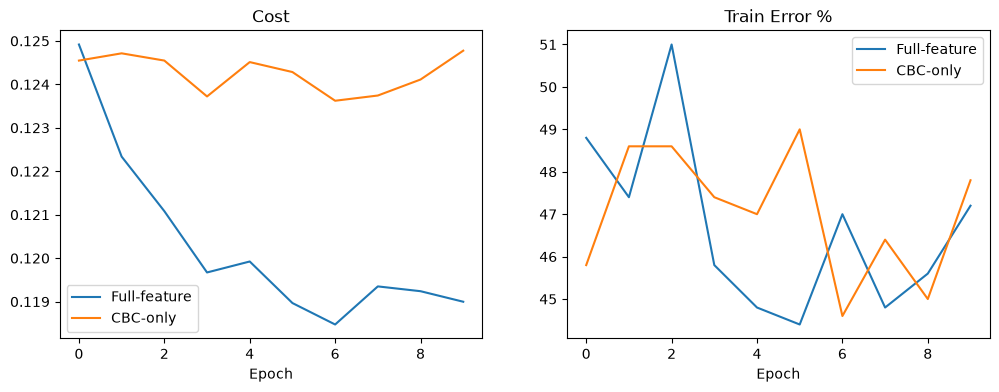

Full-feature: {'accuracy': np.float64(0.68), 'precision': 0.238, 'recall': 1.0, 'f1': 0.385, 'balanced_accuracy': 0.822, 'roc_auc': 0.884, 'pr_auc': 0.468}
CBC-only:     {'accuracy': np.float64(0.54), 'precision': 0.125, 'recall': 0.6, 'f1': 0.207, 'balanced_accuracy': 0.567, 'roc_auc': 0.709, 'pr_auc': 0.315}


In [ ]:
import numpy as np

print("=== Stability summary ===\n")

for name, results in [("Full-feature", full_feature_results), ("CBC-only", cbc_only_results)]:
    roc_aucs = [r['roc_auc'] for r in results]
    bal_accs = [r['balanced_accuracy'] for r in results]
    print(f"{name}:")
    print(f"  ROC-AUC per seed: {[round(x,3) for x in roc_aucs]}")
    print(f"  Mean ROC-AUC: {np.mean(roc_aucs):.3f}, Std: {np.std(roc_aucs):.3f}")
    print(f"  Balanced Acc per seed: {[round(x,3) for x in bal_accs]}")
    print(f"  Mean Balanced Acc: {np.mean(bal_accs):.3f}, Std: {np.std(bal_accs):.3f}\n")

# Plot cost/error curves for all seeds, one experiment at a time
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for i, seed in enumerate(SEEDS):
    axes[0,0].plot(full_feature_histories[i][0], label=f"seed={seed}")
    axes[0,1].plot(full_feature_histories[i][1], label=f"seed={seed}")
    axes[1,0].plot(cbc_only_histories[i][0], label=f"seed={seed}")
    axes[1,1].plot(cbc_only_histories[i][1], label=f"seed={seed}")

axes[0,0].set_title("Full-feature Cost"); axes[0,0].legend()
axes[0,1].set_title("Full-feature Error %"); axes[0,1].legend()
axes[1,0].set_title("CBC-only Cost"); axes[1,0].legend()
axes[1,1].set_title("CBC-only Error %"); axes[1,1].legend()
plt.tight_layout()
plt.show()

Build the circuit

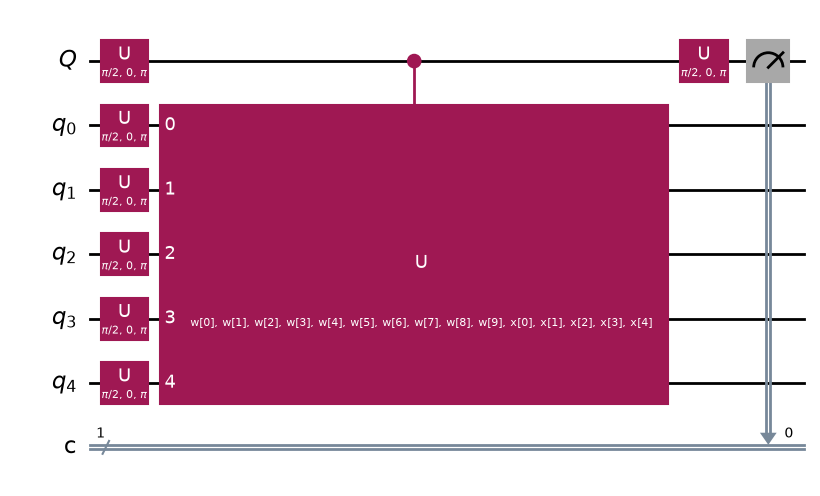

In [ ]:
qc, x_params, omega_params = build_full_pqc(num_features=5)
num_weights = len(omega_params)
qc.decompose().draw("mpl")